In [24]:
import os
import sys
from pathlib import Path

sys.path.append(os.environ['LP_ROOT'])
sys.path.append(str(Path(os.environ['PROJECT']) / 'param_search'))

import project
import param_search as ps
import torch

ps.set_backend('sge')
ps.set_verbose(False)
torch.cuda.is_available()

True

In [25]:
optim_jobs = ps.load('../bmc-4dct/2026-11-16_optimize').set_index([
    'params.curr_phase',
    'params.material_type',
    'params.tv_reg_weight',
    'params.subject'
])

job = optim_jobs.loc[0, 'LE', 0.0001, 'unknown_15_1']
job

job_name                                          job_95434cb81931dc6b
job_state                                                    COMPLETED
n_submits                                                            1
job_id                                                         8687063
node_id                                                        scc-k01
runtime                                                       00:20:16
stdout               [step 89] loss = 1.3479e-03 (delta = 1.7754e-0...
stderr                                                                
base_dir             /projectnb/batmanlab/mragoza/lung-project/note...
work_dir             /projectnb/batmanlab/mragoza/lung-project/note...
script_path          /projectnb/batmanlab/mragoza/lung-project/note...
output_path          /projectnb/batmanlab/mragoza/lung-project/note...
log_dir              /projectnb/batmanlab/mragoza/lung-project/note...
stdout_path          /projectnb/batmanlab/mragoza/lung-project/note...
stderr

In [2]:
train_jobs = ps.load('../bmc-4dct/2026-11-16_train').set_index([
    'params.curr_phase',
    'params.material_type',
    'params.tv_reg_weight',
    'params.random_seed'
])

job = train_jobs.loc[0, 'LE', 0.0001, 0]
job

job_name                                        job_6f122f283a512928
job_state                                                  COMPLETED
n_submits                                                          1
job_id                                                       8687046
node_id                                                      scc-308
runtime                                                     01:59:52
stdout             [Epoch 25 | val batch 2 | load data]  dt = 3s ...
stderr                               WARNING: No checkpoints found\n
base_dir           /projectnb/batmanlab/mragoza/lung-project/note...
work_dir           /projectnb/batmanlab/mragoza/lung-project/note...
script_path        /projectnb/batmanlab/mragoza/lung-project/note...
output_path        /projectnb/batmanlab/mragoza/lung-project/note...
log_dir            /projectnb/batmanlab/mragoza/lung-project/note...
stdout_path        /projectnb/batmanlab/mragoza/lung-project/note...
stderr_path        /projectnb/batm

In [27]:
case_id = 'unknown_13_1'
epoch = 20

In [28]:
from copy import deepcopy

def load_job_config(job):
    from pathlib import Path
    import shlex
    script = Path(job.script_path).read_text().replace('\\\n', ' ')
    command = next(l.strip() for l in script.splitlines() if l.startswith('python '))
    return project.api.get_config(shlex.split(command)[2:])

config = deepcopy(load_job_config(job))
config['dataset']['subjects'] = [case_id]
config['training']['split']['method'] = None
config['training']['loaders']['shuffle'] = False
config['training']['loaders']['batch_size'] = 1

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-16_optimize/job_95434cb81931dc6b/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      list(len=1)
|   |   └── 0: 'unknown_15_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |       ├── 0: 50
|   |       └── 1: 0
|   ├── 'variant':       datetime.date(2026, 11, 1)
|   └── 'pipeline_tags': dict(len=7)
|       ├── 'image_resampling':    'iso'
|       ├── 'image_segmentation':  'v3d'
|       ├── 'image_registration':  'gil'
|       ├── 'anatomical_regions':  'lung'
|       ├── 'mesh_generation':     'rad'
|       ├── 'field_interpolation': 'int'
|       └── 'material_properties': 'const'
├── 'preprocessing': dict(len=7)
|   ├── 'image_resampling':    dict(len=3)
|   |   ├── 'spacing':       list(len=3)
|   |   |   ├── 0: 1.0
|   | 

In [29]:
import project.training

examples = project.api.get_examples(config['dataset'])
output_dir = Path(job.work_dir) / 'outputs'

trainer = project.training.get_trainer(
    examples, config['training'], output_dir=output_dir
)
trainer.load_checkpoint(epoch=epoch)

Gathering examples...
1 total
Splitting data examples
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.weight        16	(16,)
backbone.sublevel.encoder.unit1.norm.bias          16	(16,)
backbone.sublevel.sublevel.encoder.unit0.conv.weight 13824	(32, 16, 3, 3, 3

FileNotFoundError: Checkpoint not found: /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-16_optimize/job_95434cb81931dc6b/outputs/training/default/checkpoint_20.pt

In [30]:
def check_training_physics_api(
    trainer,
    batch,
    weight=0.01,
    steps=(1e-3, 3e-3, 1e-2),
    axes=(0, 1),
):
    import numpy as np
    import pandas as pd
    import torch

    solver = trainer.adapter.pde_solver
    original_weight = solver.tv_reg_weight
    original_mode = trainer.model.training

    # This test is specifically for your E-only simulation objective.
    assert list(trainer.task.loss_targets) == ['E']
    assert trainer.task.losses['E'].upper() == 'SIM'
    assert len(batch['example']) == 1
    assert weight > 0

    task_weight = float(trainer.task.weights.get('E', 1.0))
    rows = []

    try:
        trainer.model.eval()
        with torch.no_grad():
            base = {
                key: value.detach().clone()
                for key, value in trainer.run_model(batch).items()
            }

        E = base['E']
        assert E.ndim == 5  # B, C, X, Y, Z

        for axis in axes:
            # Smooth relative perturbation: E(a) = E * (1 + a * pattern).
            dim = axis + 2
            coordinate = torch.linspace(
                0, 1, E.shape[dim], device=E.device, dtype=E.dtype
            )
            shape = [1] * E.ndim
            shape[dim] = E.shape[dim]
            pattern = torch.sin(2 * torch.pi * coordinate).reshape(shape)

            def evaluate(alpha_value, tv_weight, backward=False):
                solver.tv_reg_weight = float(tv_weight)

                with torch.enable_grad():
                    alpha = torch.tensor(
                        alpha_value,
                        device=E.device,
                        dtype=E.dtype,
                        requires_grad=backward,
                    )
                    preds = dict(base)
                    preds['E'] = E * (1 + alpha * pattern)

                    sim_loss, sims = trainer.run_physics(
                        batch, preds, eval_mode=True
                    )
                    loss = trainer.compute_loss(batch, preds, sim_loss)

                    parts = sims[0]['loss_parts']
                    values = {
                        'data': task_weight * float(parts['error_term']),
                        'tv': task_weight * float(parts['tv_reg_term']),
                        'total': float(loss.detach().item()),
                    }

                    derivative = None
                    if backward:
                        derivative = float(
                            torch.autograd.grad(loss, alpha)[0].item()
                        )

                return values, derivative

            # Complete each backward before another forward.
            v0, g0 = evaluate(0.0, 0.0, backward=True)
            vw, gw = evaluate(0.0, weight, backward=True)

            np.testing.assert_allclose(
                vw['data'], v0['data'], rtol=1e-5, atol=1e-8
            )
            np.testing.assert_allclose(
                vw['total'],
                vw['data'] + vw['tv'],
                rtol=1e-5,
                atol=1e-8,
            )

            analytic = {
                'data': g0,
                'tv': gw - g0,
                'total': gw,
            }

            for h in steps:
                plus, _ = evaluate(h, weight)
                minus, _ = evaluate(-h, weight)

                for component in ('data', 'tv', 'total'):
                    fd = (
                        plus[component] - minus[component]
                    ) / (2 * h)
                    ad = analytic[component]

                    rows.append({
                        'axis': axis,
                        'component': component,
                        'step': h,
                        'finite_difference': fd,
                        'backward_derivative': ad,
                        'FD/backward': fd / ad if ad else np.nan,
                        'relative_error': abs(fd - ad) / max(
                            abs(fd), abs(ad), 1e-12
                        ),
                    })

        return pd.DataFrame(rows)

    finally:
        solver.tv_reg_weight = original_weight
        trainer.model.train(original_mode)

checks = check_training_physics_api(trainer, batch)
display(checks)

,axis,component,step,finite_difference,backward_derivative,FD/backward,relative_error
0,0,data,0.001,3.774650e-03,3.767767e-03,1.001827,0.001824
1,0,tv,0.001,1.862645e-06,1.782784e-06,1.044796,0.042875
2,0,total,0.001,3.776513e-03,3.769550e-03,1.001847,0.001844
3,0,data,0.003,3.769994e-03,3.767767e-03,1.000591,0.000591
4,0,tv,0.003,1.785035e-06,1.782784e-06,1.001262,0.001261
5,0,total,0.003,3.771856e-03,3.769550e-03,1.000612,0.000611
6,0,data,0.010,3.767759e-03,3.767767e-03,0.999998,0.000002
7,0,tv,0.010,1.781154e-06,1.782784e-06,0.999086,0.000914
8,0,total,0.010,3.769528e-03,3.769550e-03,0.999994,0.000006
9,1,data,0.001,1.032930e-02,1.032588e-02,1.000331,0.000331


In [31]:
def check_inversion_physics_api(
    adapter,
    mesh,
    unit_m,
    bc_spec,
    param_dict,
    weight=0.01,
    steps=(1e-3, 3e-3, 1e-2),
    n_directions=2,
    global_mean=False,
    seed=123,
):
    import numpy as np
    import pandas as pd
    import torch

    solver = adapter.pde_solver
    original_weight = solver.tv_reg_weight
    parameters = [p for p in param_dict.parameters() if p.requires_grad]
    assert parameters, 'No trainable inversion parameters'
    assert weight > 0

    originals = [p.detach().clone() for p in parameters]
    original_grads = [
        None if p.grad is None else p.grad.detach().clone()
        for p in parameters
    ]
    rng = torch.Generator(device='cpu').manual_seed(seed)
    rows = []

    try:
        for direction_id in range(n_directions):
            # Perturb the actual unconstrained optimization variables.
            directions = []
            for p in parameters:
                d = torch.randn(
                    p.shape, generator=rng, dtype=torch.float64
                )
                d /= d.square().mean().sqrt().clamp_min(1e-12)
                directions.append(d.to(device=p.device, dtype=p.dtype))

            def evaluate(alpha, tv_weight, backward=False):
                solver.tv_reg_weight = float(tv_weight)

                with torch.no_grad():
                    for p, initial, d in zip(
                        parameters, originals, directions
                    ):
                        p.copy_(initial + alpha * d)

                for p in parameters:
                    p.grad = None

                with torch.set_grad_enabled(backward):
                    # Same decoding/mapping call as the L-BFGS closure.
                    params = param_dict(global_mean)

                    loss, sim = adapter.mesh_simulation_loss(
                        mesh, unit_m, params, bc_spec, True
                    )
                    parts = sim['loss_parts']
                    values = {
                        'data': float(parts['error_term']),
                        'tv': float(parts['tv_reg_term']),
                        'total': float(loss.detach().item()),
                    }

                    derivative = None
                    if backward:
                        loss.backward()
                        derivative = 0.0
                        for p, d in zip(parameters, directions):
                            if p.grad is not None:
                                if not torch.isfinite(p.grad).all():
                                    raise RuntimeError(
                                        'Non-finite inversion gradient'
                                    )
                                derivative += (
                                    p.grad.detach().double() * d.double()
                                ).sum().item()

                return values, derivative

            # Separate forward/backward calls at the same parameter state.
            data_values, data_grad = evaluate(
                0.0, 0.0, backward=True
            )
            full_values, full_grad = evaluate(
                0.0, weight, backward=True
            )

            np.testing.assert_allclose(
                full_values['data'], data_values['data'],
                rtol=1e-5, atol=1e-8,
            )
            np.testing.assert_allclose(
                full_values['total'],
                full_values['data'] + full_values['tv'],
                rtol=1e-5, atol=1e-8,
            )

            analytic = {
                'data': data_grad,
                'tv': full_grad - data_grad,
                'total': full_grad,
            }

            for h in steps:
                plus, _ = evaluate(h, weight)
                minus, _ = evaluate(-h, weight)

                for component in ('data', 'tv', 'total'):
                    fd = (
                        plus[component] - minus[component]
                    ) / (2 * h)
                    ad = analytic[component]

                    rows.append({
                        'direction': direction_id,
                        'component': component,
                        'step': h,
                        'finite_difference': fd,
                        'backward_derivative': ad,
                        'FD/backward': fd / ad if ad else np.nan,
                        'relative_error': abs(fd - ad) / max(
                            abs(fd), abs(ad), 1e-12
                        ),
                    })

        return pd.DataFrame(rows)

    finally:
        solver.tv_reg_weight = original_weight
        with torch.no_grad():
            for p, initial, grad in zip(
                parameters, originals, original_grads
            ):
                p.copy_(initial)
                p.grad = grad

def check_inversion_from_config(
    config,
    case_id,
    weight=0.01,
    steps=(1e-3, 3e-3, 1e-2),
    n_directions=2,
    seed=123,
):
    from copy import deepcopy
    import torch
    import project.api
    import project.optimization as opt

    config = deepcopy(config)
    config['dataset']['subjects'] = [case_id]

    examples = project.api.get_examples(config['dataset'])
    assert len(examples) == 1
    ex = examples[0]
    cfg = config['optimization']

    sample = opt.datasets.load_example(ex, verbose=True)
    mesh = sample['mesh']
    unit_m = float(ex.metadata['unit'])

    solver = opt.physics.get_solver(**cfg.get('pde_solver', {}))
    adapter = opt.physics.get_adapter(
        solver, **cfg.get('physics_adapter', {})
    )
    bc_spec = opt.physics.get_bc_spec(
        **cfg.get('boundary_condition', {})
    )

    dof_mapper = opt.make_surface_mapper(
        mesh.points, mesh.cells_dict['tetra']
    )
    dof_mapper = opt._as_sparse_tensor(
        dof_mapper, torch.float32, adapter.device
    )

    template = adapter.initialize_scalar_field(mesh, unit_m)
    param_dict = opt.ParameterDict(
        template, dof_mapper, **cfg.get('parameters', {})
    )

    init_scale = cfg.get('optimization_kws', {}).get('init_scale', 0.1)
    if init_scale <= 0:
        raise ValueError(
            'Use a positive init_scale for this TV check; '
            'a uniform initialization does not exercise spatial TV.'
        )

    init_seed = cfg.get('seed')
    torch.manual_seed(seed if init_seed is None else init_seed)
    param_dict.initialize(init_scale)

    return check_inversion_physics_api(
        adapter=adapter,
        mesh=mesh,
        unit_m=unit_m,
        bc_spec=bc_spec,
        param_dict=param_dict,
        weight=weight,
        steps=steps,
        n_directions=n_directions,
        global_mean=False,
        seed=seed,
    )

checks_optim = check_inversion_from_config(
    config,
    case_id='4DCT_1_1',
    weight=0.01,
)
display(checks_optim)

Gathering examples...
1 total
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/images/4DCT_1_1_50_iso.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d_domain.nii.gz
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/meshes/4DCT_1_1_50_iso_v3d_gil_0_lung_rad_const_int.xdmf


,direction,component,step,finite_difference,backward_derivative,FD/backward,relative_error
0,0,data,0.001,-0.000057,-0.000054,1.051199,0.048705
1,0,tv,0.001,-0.000134,-0.000134,1.000368,0.000368
2,0,total,0.001,-0.000191,-0.000188,1.013718,0.013532
3,0,data,0.003,-0.000057,-0.000054,1.062688,0.058990
4,0,tv,0.003,-0.000134,-0.000134,0.997767,0.002233
5,0,total,0.003,-0.000192,-0.000188,1.017014,0.016730
6,0,data,0.010,-0.000055,-0.000054,1.009840,0.009745
7,0,tv,0.010,-0.000132,-0.000134,0.982337,0.017663
8,0,total,0.010,-0.000187,-0.000188,0.990476,0.009524
9,1,data,0.001,0.000473,0.000522,0.906477,0.093523


In [6]:
def check_tv_gradient(trainer, batch, weight=0.01):
    import torch

    solver = trainer.adapter.pde_solver
    original_weight = solver.tv_reg_weight
    original_mode = trainer.model.training
    params = [p for p in trainer.model.parameters() if p.requires_grad]

    def compute(tv_weight):
        solver.tv_reg_weight = tv_weight

        with torch.enable_grad():
            preds = trainer.run_model(batch)
            sim_loss, sims = trainer.run_physics(
                batch, preds, eval_mode=True
            )
            loss = trainer.compute_loss(batch, preds, sim_loss)

            # One backward per fresh forward; no clipping or optimizer step.
            grads = torch.autograd.grad(
                loss, params, allow_unused=True
            )

        flat_grad = torch.cat([
            (
                torch.zeros_like(p) if g is None else g
            ).detach().reshape(-1).cpu().double()
            for p, g in zip(params, grads)
        ])

        return {
            'gradient': flat_grad,
            'loss': loss.item(),
            'parts': [dict(sim['loss_parts']) for sim in sims],
            'prediction': preds['E'].detach().cpu().clone(),
            'connected_parameters': sum(g is not None for g in grads),
        }

    try:
        trainer.model.eval()
        data = compute(0.0)
        combined = compute(weight)
    finally:
        solver.tv_reg_weight = original_weight
        trainer.model.train(original_mode)

    g_data = data['gradient']
    g_total = combined['gradient']
    g_tv = g_total - g_data

    n_data = g_data.norm().item()
    n_total = g_total.norm().item()
    n_tv = g_tv.norm().item()

    stats = {
        'max_prediction_difference': (
            combined['prediction'] - data['prediction']
        ).abs().max().item(),
        'data_loss': data['loss'],
        'combined_loss': combined['loss'],
        'data_grad_norm': n_data,
        'total_grad_norm': n_total,
        'weighted_tv_grad_norm': n_tv,
        'tv/data_grad_ratio': n_tv / n_data if n_data else float('nan'),
        'data_tv_cosine': (
            torch.dot(g_data, g_tv).item() / (n_data * n_tv)
            if n_data and n_tv else float('nan')
        ),
        'all_gradients_finite': bool(
            torch.isfinite(g_data).all()
            and torch.isfinite(g_total).all()
        ),
    }

    return stats, {
        'data_parts': data['parts'],
        'combined_parts': combined['parts'],
        'g_data': g_data,
        'g_weighted_tv': g_tv,
        'g_total': g_total,
    }

batch = next(iter(trainer.train_loader))
stats, diagnostic = check_tv_gradient(trainer, batch, weight=0.01)
project.utils.pprint(stats)
print('Data-only loss components:')
project.utils.pprint(diagnostic['data_parts'])
print('Combined loss components:')
project.utils.pprint(diagnostic['combined_parts'])

dict(len=9)
├── 'max_prediction_difference': 0.0
├── 'data_loss':                 0.017820915207266808
├── 'combined_loss':             0.019981874153017998
├── 'data_grad_norm':            1.0925954449365973
├── 'total_grad_norm':           1.2361311368160663
├── 'weighted_tv_grad_norm':     0.18946345809177115
├── 'tv/data_grad_ratio':        0.1734067801305593
├── 'data_tv_cosine':            0.7206498017246858
└── 'all_gradients_finite':      True
Data-only loss components:
list(len=1)
└── 0: dict(len=5)
    ├── 'error_num':   7.76903164023679e-09
    ├── 'error_den':   4.359492322691949e-07
    ├── 'error_term':  0.017820915207266808
    ├── 'tv_reg_val':  0.21609586477279663
    └── 'tv_reg_term': 0.0
Combined loss components:
list(len=1)
└── 0: dict(len=5)
    ├── 'error_num':   7.76903164023679e-09
    ├── 'error_den':   4.359492322691949e-07
    ├── 'error_term':  0.017820915207266808
    ├── 'tv_reg_val':  0.21609586477279663
    └── 'tv_reg_term': 0.0021609587129205465


In [7]:
def finite_difference_tv(trainer, batch, weight=0.01,
                         steps=(1e-4, 1e-3, 1e-2)):
    import torch
    import pandas as pd

    # Fresh forward/backward passes at the current checkpoint.
    stats, diagnostic = check_tv_gradient(trainer, batch, weight)
    g_tv = diagnostic['g_weighted_tv']
    norm = g_tv.norm().item()
    if not norm > 0:
        raise ValueError('TV gradient is zero; no direction to test.')

    # Unit direction in network-parameter space.
    direction = g_tv / norm
    params = [p for p in trainer.model.parameters() if p.requires_grad]
    originals = [p.detach().clone() for p in params]

    directions = []
    offset = 0
    for p in params:
        directions.append(
            direction[offset:offset + p.numel()]
            .reshape(p.shape).to(device=p.device, dtype=p.dtype)
        )
        offset += p.numel()

    solver = trainer.adapter.pde_solver
    original_weight = solver.tv_reg_weight
    original_mode = trainer.model.training

    @torch.no_grad()
    def evaluate_at(step):
        # Always perturb from the original weights.
        for p, original, d in zip(params, originals, directions):
            p.copy_(original + step * d)

        preds = trainer.run_model(batch)
        _, sims = trainer.run_physics(batch, preds, eval_mode=True)

        # Same batch averaging and SIM task weighting as compute_loss.
        sim_weight = sum(
            trainer.task.weights.get(target, 1.0)
            for target in trainer.task.loss_targets
            if trainer.task.losses[target].upper() == 'SIM'
        )
        return (
            sim_weight * weight
            * sum(s['loss_parts']['reg'] for s in sims) / len(sims)
        )

    rows = []
    try:
        trainer.model.eval()
        solver.tv_reg_weight = weight

        for h in steps:
            plus = evaluate_at(h)
            minus = evaluate_at(-h)
            finite_difference = (plus - minus) / (2 * h)

            rows.append({
                'step': h,
                'weighted_TV_minus': minus,
                'weighted_TV_plus': plus,
                'finite_difference': finite_difference,
                'backward_derivative': norm,
                'FD/backward': finite_difference / norm,
            })
    finally:
        with torch.no_grad():
            for p, original in zip(params, originals):
                p.copy_(original)
        solver.tv_reg_weight = original_weight
        trainer.model.train(original_mode)

    return pd.DataFrame(rows)

fd_results = finite_difference_tv(trainer, batch, weight=0.01)
display(fd_results)

,step,weighted_TV_minus,weighted_TV_plus,finite_difference,backward_derivative,FD/backward
0,0.0001,0.004324,0.004320,-0.020257,0.000004,-5361.989103
1,0.0010,0.004347,0.004298,-0.024604,0.000004,-6512.801182
2,0.0100,0.004584,0.004099,-0.024235,0.000004,-6415.169908


In [16]:
def check_isolated_tv(trainer, batch, steps=(1e-4, 1e-3, 1e-2)):
    import numpy as np
    import pandas as pd
    import torch
    import warp as wp
    from project.common import transforms
    from project.common.interpolation import interpolate_tensor
    from project.physics.warp import forms

    adapter = trainer.adapter
    solver = adapter.pde_solver
    original_mode = trainer.model.training

    try:
        trainer.model.eval()

        # Reproduce the adapter's voxel-to-mesh sampling.
        with torch.no_grad():
            preds = trainer.run_model(batch)
            ctx = adapter.get_physics_context(
                batch['mesh'][0],
                batch['example'][0].metadata['unit'],
            )
            points = ctx.points[adapter.scalar_degree].to(adapter.device)
            affine = batch['affine'][0].to(adapter.device)
            voxels = transforms.world_to_voxel_coords(points, affine)

            params = {
                key: interpolate_tensor(
                    preds[key][0].to(adapter.device), voxels
                )[:, 0]
                for key in trainer.task.physics_targets
            }
            mu, _, _ = adapter.get_canonical_parameters(ctx, params)
            values = mu.detach().cpu().numpy().copy()

        solver.bind_geometry(ctx.verts, ctx.cells)

        # Fixed, smooth relative perturbation, independent of backward.
        xyz = points.detach().cpu().numpy().astype(np.float64)
        span = np.ptp(xyz, axis=0)
        axis = int(span.argmax())
        coordinate = (
            (xyz[:, axis] - xyz[:, axis].min()) / span[axis]
        )
        direction = values.astype(np.float64) * np.sin(
            2 * np.pi * coordinate
        )

        def evaluate(v, backward=False):
            with wp.ScopedDevice(solver.device):
                field = solver.init_scalar_field(
                    np.asarray(v, dtype=values.dtype),
                    requires_grad=backward,
                )
                loss = wp.zeros(
                    1, dtype=solver.scalar_dtype,
                    requires_grad=backward,
                )

                def integrate():
                    wp.fem.integrate(
                        forms.TV_reg_form,
                        fields={'f': field},
                        values={
                            'eps_div': solver.eps_div,
                            'eps_reg': solver.eps_reg,
                        },
                        domain=solver.interior,
                        output=loss,
                    )

                if backward:
                    tape = wp.Tape()
                    with tape:
                        integrate()
                    tape.backward(loss=loss)
                    grad = (
                        wp.to_torch(field.dof_values.grad)
                        .detach().cpu().numpy().copy()
                    )
                else:
                    integrate()
                    grad = None

                value = wp.to_torch(loss).item()

            return value, grad

        base, grad = evaluate(values, backward=True)
        analytic = np.dot(
            grad.astype(np.float64).ravel(), direction.ravel()
        )

        rows = []
        for h in steps:
            plus, _ = evaluate(values + h * direction)
            minus, _ = evaluate(values - h * direction)
            fd = (plus - minus) / (2 * h)

            rows.append({
                'step': h,
                'TV_minus': minus,
                'TV_plus': plus,
                'finite_difference': fd,
                'backward_derivative': analytic,
                'FD/backward': fd / analytic if analytic != 0 else np.nan,
            })

        print('Unweighted mu TV:', base)
        print('Gradient norm:', np.linalg.norm(grad))
        print('Gradient finite:', np.isfinite(grad).all())
        return pd.DataFrame(rows)

    finally:
        trainer.model.train(original_mode)

display(check_isolated_tv(trainer, batch))

Unweighted mu TV: 0.21609586477279663
Gradient norm: 1.7081782e-05
Gradient finite: True


,step,TV_minus,TV_plus,finite_difference,backward_derivative,FD/backward
0,0.0001,0.216096,0.216096,0.000522,0.000556,0.937517
1,0.0010,0.216095,0.216096,0.000559,0.000556,1.004483
2,0.0100,0.216091,0.216102,0.000557,0.000556,1.000465


Reg at weight 0 / requested weight: 0.43219396471977234 0.43219396471977234
Data mu-gradient norm: 3.1553356092769866e-07
Weighted TV mu-gradient norm: 2.7234304888456317e-13


,step,weighted_TV_minus,weighted_TV_plus,finite_difference,backward_derivative,FD/backward
0,0.0001,0.004322,0.004322,0.000006,-8.980861e-11,-66368.515924
1,0.0010,0.004322,0.004322,0.000006,-8.980861e-11,-61390.877229
2,0.0100,0.004322,0.004322,0.000006,-8.980861e-11,-61888.641099


In [25]:
import warp as wp

@wp.fem.integrand
def debug_tv_mu(
    x: wp.fem.Sample, f_mu: wp.fem.Field,
    eps_reg: float, eps_div: float,
):
    g = wp.fem.grad(f_mu, x) / (f_mu(x) + eps_div)
    return wp.sqrt(wp.dot(g, g) + eps_reg * eps_reg)


@wp.fem.integrand
def debug_tv_lam(
    x: wp.fem.Sample, f_lam: wp.fem.Field,
    eps_reg: float, eps_div: float,
):
    g = wp.fem.grad(f_lam, x) / (f_lam(x) + eps_div)
    return wp.sqrt(wp.dot(g, g) + eps_reg * eps_reg)


@wp.fem.integrand
def debug_tv_rho(
    x: wp.fem.Sample, f_rho: wp.fem.Field,
    eps_reg: float, eps_div: float,
):
    g = wp.fem.grad(f_rho, x) / (f_rho(x) + eps_div)
    return wp.sqrt(wp.dot(g, g) + eps_reg * eps_reg)


def check_fixed_state_tv(
    trainer, batch, weight=0.01, steps=(1e-4, 1e-3, 1e-2)
):
    import numpy as np
    import pandas as pd
    import torch
    import warp as wp
    from project.common import transforms
    from project.common.interpolation import interpolate_tensor

    adapter = trainer.adapter
    solver = adapter.pde_solver
    original_weight = solver.tv_reg_weight
    original_mode = trainer.model.training

    try:
        trainer.model.eval()

        # Same mesh inputs as the previous test.
        with torch.no_grad():
            preds = trainer.run_model(batch)
            ctx = adapter.get_physics_context(
                batch['mesh'][0],
                batch['example'][0].metadata['unit'],
            )
            points = ctx.points[adapter.scalar_degree].to(adapter.device)
            affine = batch['affine'][0].to(adapter.device)
            voxels = transforms.world_to_voxel_coords(points, affine)

            params = {
                key: interpolate_tensor(
                    preds[key][0].to(adapter.device), voxels
                )[:, 0]
                for key in trainer.task.physics_targets
            }
            mu, lam, rho = adapter.get_canonical_parameters(ctx, params)
            u_bc, u_obs = adapter.get_observation_pair(ctx, trainer.bc_spec)

        mu, lam, rho, u_bc, u_obs = [
            t.detach().clone() for t in (mu, lam, rho, u_bc, u_obs)
        ]
        mask = torch.ones(
            u_obs.shape[0], dtype=mu.dtype, device=mu.device
        )

        solver.bind_geometry(ctx.verts, ctx.cells)

        # Solve once, outside every differentiation tape.
        u_fixed = solver.solve_forward(mu, lam, rho, u_bc).detach().clone()

        xyz = points.detach().cpu().numpy().astype(np.float64)
        span = np.ptp(xyz, axis=0)
        axis = int(span.argmax())
        coordinate = (xyz[:, axis] - xyz[:, axis].min()) / span[axis]
        direction = mu * torch.as_tensor(
            np.sin(2 * np.pi * coordinate),
            dtype=mu.dtype, device=mu.device,
        )

        # INDENT TO HERE
        def evaluate(mu_values, backward=False):
            from project.physics.warp import forms
        
            with wp.ScopedDevice(solver.device):
                m = solver.init_scalar_field(
                    mu_values, requires_grad=backward
                )
                l = solver.init_scalar_field(lam, requires_grad=False)
                r = solver.init_scalar_field(rho, requires_grad=False)
        
                # Keep separate stores alive through backward.
                stores = [wp.fem.TemporaryStore() for _ in range(3)]
                
                tape = wp.Tape()
                with tape:
                    terms = []
                    specs = [
                        (debug_tv_lam, 'f_lam', l),
                        (debug_tv_rho, 'f_rho', r),
                        (debug_tv_mu, 'f_mu', m),
                    ]
                    
                    for (form, field_name, field), store in zip(specs, stores):
                        term = wp.zeros(
                            1, dtype=solver.scalar_dtype, requires_grad=backward
                        )
                        wp.fem.integrate(
                            form,
                            fields={field_name: field},
                            values={
                                'eps_div': solver.eps_div,
                                'eps_reg': solver.eps_reg,
                            },
                            domain=solver.interior,
                            output=term,
                            temporary_store=store,
                        )
                        terms.append(term)
                    
                    reg = terms[0] + terms[1] + terms[2]
                    weighted_reg = weight * reg
                
                    reg = terms[0] + terms[1] + terms[2]  # Still test μ only.
                    weighted_reg = weight * reg
        
                reg_value = wp.to_torch(reg).item()
        
                grad = None
                if backward:
                    print(pd.DataFrame([
                        {
                            'term': name,
                            'value': float(term.numpy()[0]),
                            'value_ptr': term.ptr,
                            'grad_ptr': (
                                term.grad.ptr if term.grad is not None else None
                            ),
                        }
                        for name, term in zip(('lam', 'rho', 'mu'), terms)
                    ]).to_string(index=False))
                    
                    print(pd.DataFrame([
                        {
                            'field': name,
                            'value_ptr': field.dof_values.ptr,
                            'grad_ptr': (
                                field.dof_values.grad.ptr
                                if field.dof_values.grad is not None else None
                            ),
                        }
                        for name, field in (('lam', l), ('rho', r), ('mu', m))
                    ]).to_string(index=False))
                    tape.backward(loss=weighted_reg)
                    grad = (
                        wp.to_torch(m.dof_values.grad)
                        .detach().cpu().double().clone()
                    )
        
            return reg_value, grad

        solver.tv_reg_weight = weight
        reg, grad = evaluate(mu, backward=True)

        # With u fixed, the displacement term has no mu dependence.
        analytic = (
            grad * direction.detach().cpu().double()
        ).sum().item()

        rows = []
        for h in steps:
            plus, _ = evaluate(mu + h * direction)
            minus, _ = evaluate(mu - h * direction)
            fd = weight * (plus - minus) / (2 * h)

            rows.append({
                'step': h,
                'finite_difference': fd,
                'backward_derivative': analytic,
                'FD/backward': fd / analytic if analytic else np.nan,
            })

        print('Unweighted total TV:', reg)
        print('Weighted TV mu-gradient norm:', grad.norm().item())
        return pd.DataFrame(rows)

    finally:
        solver.tv_reg_weight = original_weight
        trainer.model.train(original_mode)

display(check_fixed_state_tv(trainer, batch))

term    value   value_ptr    grad_ptr
 lam 0.216096 12956456448 13017075200
 rho 0.000002 12918906880 12918907392
  mu 0.216096 12956459008 12956459520
field   value_ptr     grad_ptr
  lam 13098963456          NaN
  rho 13099113472          NaN
   mu 12955855360 1.295768e+10
Unweighted total TV: 0.43219396471977234
Weighted TV mu-gradient norm: 1.708178165343711e-07


,step,finite_difference,backward_derivative,FD/backward
0,0.0001,0.000004,0.000006,0.803586
1,0.0010,0.000006,0.000006,1.017875
2,0.0100,0.000006,0.000006,1.001803


In [14]:
import inspect

print(inspect.getsource(type(trainer.adapter.pde_solver).evaluate_loss))
print(inspect.getsource(check_fixed_state_tv))

    def evaluate_loss(self, mu, lam, rho, u_sim, u_obs, mask):

        # relative error numerator and denominator
        num = wp.empty(1, dtype=self.scalar_dtype, requires_grad=True)
        den = wp.empty(1, dtype=self.scalar_dtype, requires_grad=True)

        wp.fem.integrate(
            forms.squared_error_form,
            fields={'u': u_sim, 'v': u_obs, 'w': mask},
            domain=self.interior,
            output=num
        )

        if self.relative_loss:
            wp.fem.integrate(
                forms.squared_norm_form,
                fields={'u': u_obs, 'w': mask},
                domain=self.interior,
                output=den
            )
        else:
            wp.fem.integrate(
                forms.volume_form,
                fields={'w': mask},
                domain=self.interior,
                output=den
            )

        reg_terms = []
        for field in (mu, lam, rho):
            term = wp.empty(1, dtype=self.scalar_dtype, requires_grad=

In [4]:
%%time
case_id = '4DCT_1_1'
epochs  = [0, 5, 10, 15, 20]
weights = [1e-4, 1e-3, 1e-2]

E_pred_grid = {}
E_raster_grid = {}

rows = []
for weight in weights:
    criteria = {
        'params.curr_phase': 0,
        'params.material_type': 'LE',
        'params.tv_reg_weight': weight,
        'params.random_seed': 0
    }
    selected_job = train_jobs.loc[
        tuple(criteria[key] for key in train_jobs.index.names)
    ]

    E_pred_grid[weight] = {}
    E_raster_grid[weight] = {}

    for epoch in epochs:
        E_pred, E_raster, loss_parts, example, _ = run_inference(selected_job, case_id, epoch)
        E_pred_grid[weight][epoch] = E_pred
        E_raster_grid[weight][epoch] = E_raster
        rows.append({
            'weight': weight,
            'epoch': epoch,
            'loss_total': loss_parts['total'],
            'loss_num': loss_parts['num'],
            'loss_den': loss_parts['den'],
            'loss_err': loss_parts['err'],
            'loss_reg': loss_parts['reg'],
            'loss_weighted_reg': loss_parts['weighted_reg']
        })

mask = project.fileio.load_nibabel(example.paths['domain_mask']).get_fdata()

Loading /projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct/2026-11-16_train/job_6f122f283a512928/config/7376b2cbfa0ad26e.yaml
dict(len=4)
├── 'dataset':       dict(len=6)
|   ├── 'name':          'BMC-4DCT'
|   ├── 'root':          '/restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT'
|   ├── 'subjects':      '4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4DCT_7_3,4DCT_8_1,4DCT_8_2,4DCT_10_1,unknown_12_1,unknown_13_1,unknown_14_1,unknown_15_1,unknown_16_1,unknown_17_1,unknown_17_3,unknown_18_1,unknown_19_1,unknown_20_1,unknown_22_1,unknown_23_1,unknown_26_1,unknown_27_1,unknown_28_1,unknown_29_1,unknown_30_1,unknown_31_1,unknown_32_1,unknown_33_1,unknown_34_1,unknown_36_1,unknown_37_1,unknown_38_1,unknown_39_1,unknown_40_1,unknown_40_5,unknown_42_1,unknown_42_4,unknown_43_1,unknown_44_1,unknown_45_1,unknown_47_1,unknown_49_1,unknown_50_1,unknown_51_1,unknown_52_1,unknown_53_1'
|   ├── 'state_pairs':   list(len=1)
|   |   └── 0: list(len=2)
|   |       ├── 0: 50
|   |       └

In [5]:
mask = project.fileio.load_nibabel(example.paths['domain_mask']).get_fdata()
mask.shape

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/masks/4DCT_1_1_50_iso_v3d_domain.nii.gz


(500, 500, 349)

In [7]:
import pandas as pd
loss_df = pd.DataFrame(rows)

display(loss_df.pivot(
    index='epoch',
    columns='weight',
    values=['loss_err', 'loss_reg', 'loss_weighted_reg'],
))

loss_err                      loss_reg                      \
weight    0.0001    0.0010    0.0100    0.0001    0.0010    0.0100   
epoch                                                                
0       0.017821  0.017821  0.017821  0.432194  0.432194  0.432194   
5       0.020928  0.020757  0.020809  2.353583  2.378329  2.360026   
10      0.019265  0.020003  0.019077  2.714118  2.712780  2.741903   
15      0.019852  0.020964  0.019328  2.556745  2.545626  2.559688   
20      0.019234  0.019399  0.018507  2.747624  2.763477  2.806160   

       loss_weighted_reg                      
weight            0.0001    0.0010    0.0100  
epoch                                         
0               0.000043  0.000432  0.004322  
5               0.000235  0.002378  0.023600  
10              0.000271  0.002713  0.027419  
15              0.000256  0.002546  0.025597  
20              0.000275  0.002763  0.028062

In [42]:
def plot_weight_epoch_grid(E_grid, mask, z=None):
    weights = sorted(E_grid)
    epochs = sorted(E_grid[weights[0]])
    mask = np.asarray(mask, dtype=bool)

    if z is None:
        z = int(mask.sum(axis=(0, 1)).argmax())

    xy = np.argwhere(mask[:, :, z])
    lo = np.maximum(xy.min(axis=0) - 10, 0)
    hi = np.minimum(xy.max(axis=0) + 11, mask.shape[:2])
    crop = (slice(lo[0], hi[0]), slice(lo[1], hi[1]), z)
    mask_slice = mask[crop].T

    fig, axes = plt.subplots(
        len(weights), len(epochs),
        figsize=(3 * len(epochs), 3 * len(weights)),
        squeeze=False, layout='constrained',
    )
    norm = LogNorm(vmin=0.1, vmax=100)

    for row, weight in enumerate(weights):
        for col, epoch in enumerate(epochs):
            ax = axes[row, col]
            field = np.ma.masked_where(
                ~mask_slice,
                E_grid[weight][epoch][crop].T / 1000,
            )
            im = ax.imshow(
                field, origin='lower', cmap='turbo', norm=norm,
            )
            ax.set_xticks([])
            ax.set_yticks([])

            if row == 0:
                ax.set_title(f'Epoch {epoch}')
            if col == 0:
                ax.set_ylabel(f'TV = {weight:g}')

    fig.colorbar(
        im, ax=axes.ravel().tolist(),
        label='Young’s modulus (kPa)', shrink=0.8,
    )
    return fig, axes, z

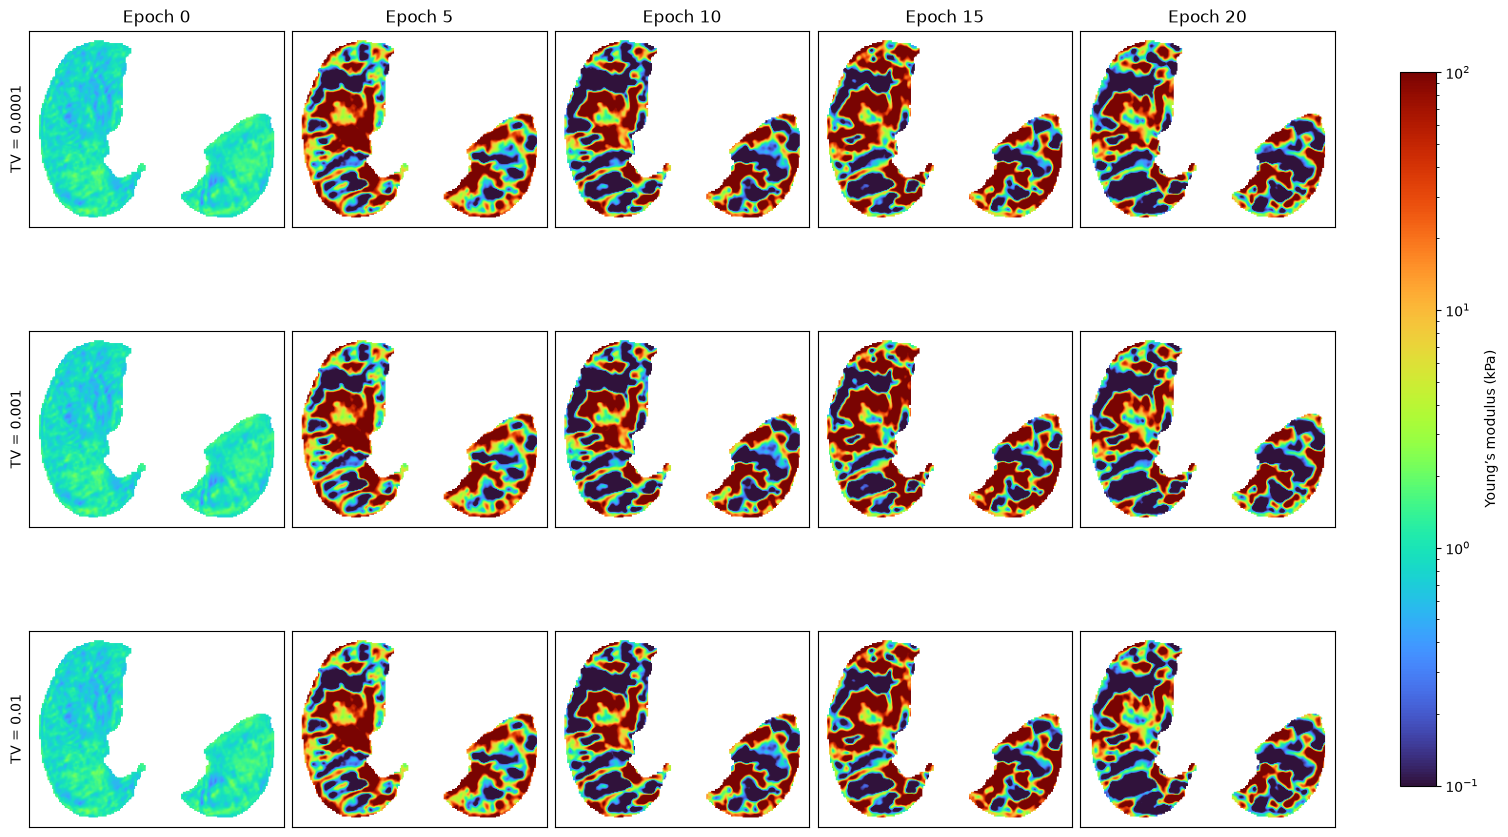

In [50]:
fig, axes, z = plot_weight_epoch_grid(E_pred_grid, mask)

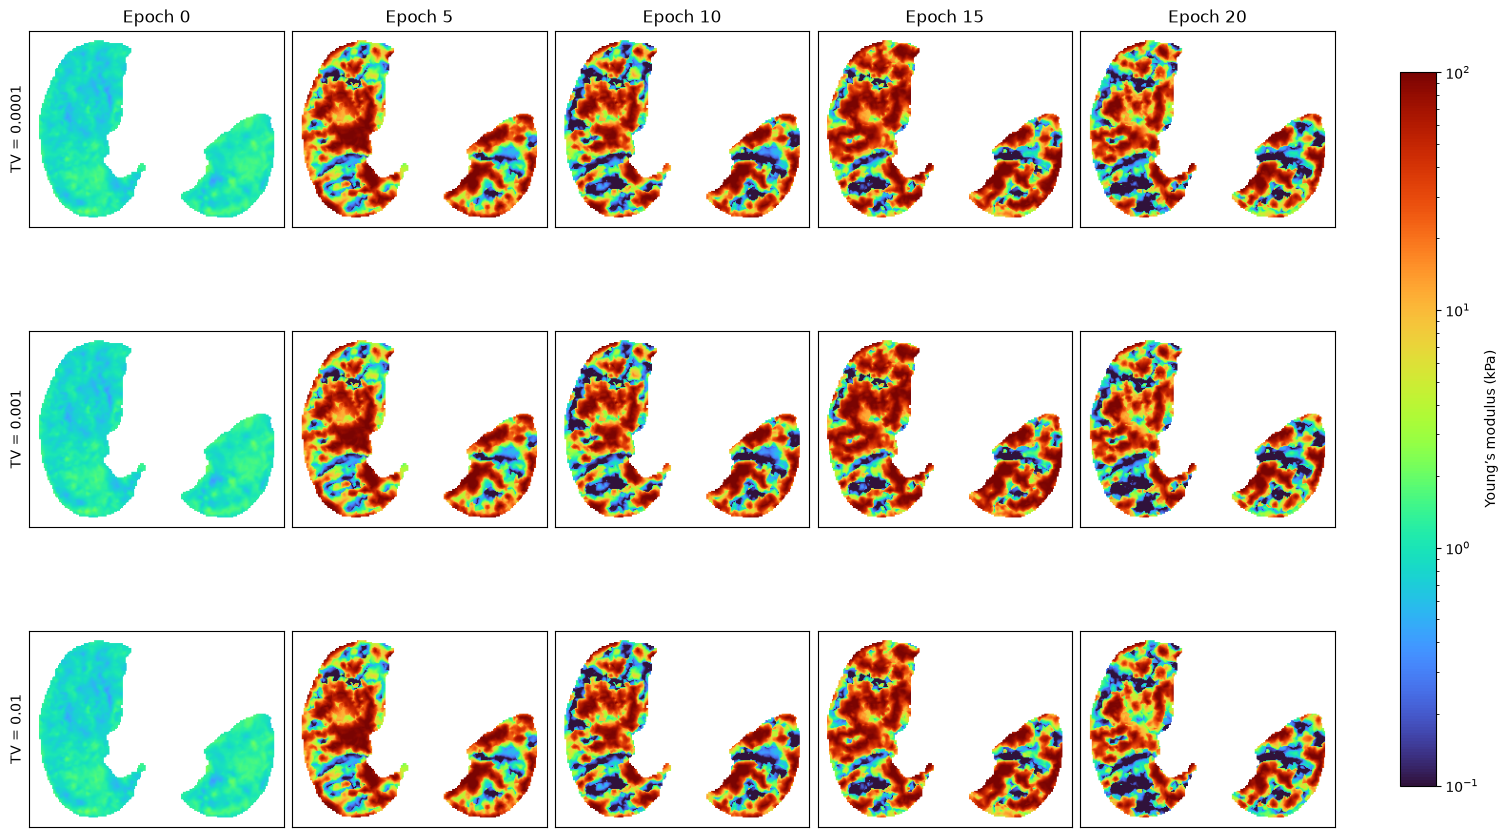

In [51]:
fig, axes, z = plot_weight_epoch_grid(E_raster_grid, mask)